In [ ]:
!pip install -q ucimlrepo

from ucimlrepo import fetch_ucirepo

breast_cancer = fetch_ucirepo(id=17)

X = breast_cancer.data.features.copy()
y = breast_cancer.data.targets.copy()

print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
display(y.head())

Features shape: (569, 30)
Target shape: (569, 1)


,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,radius3,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


,Diagnosis
0,M
1,M
2,M
3,M
4,M


In [ ]:
print("Dataset information:")
X.info()

print("\nMissing values in features:", X.isnull().sum().sum())
print("Duplicate rows in features:", X.duplicated().sum())

print("\nMissing values in target:", y.isnull().sum().sum())
print("Duplicate column names:", X.columns.duplicated().sum())

print("\nDiagnosis distribution:")
print(y['Diagnosis'].value_counts())

print("\nStatistical summary:")
display(X.describe().T)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   radius1             569 non-null    float64
 1   texture1            569 non-null    float64
 2   perimeter1          569 non-null    float64
 3   area1               569 non-null    float64
 4   smoothness1         569 non-null    float64
 5   compactness1        569 non-null    float64
 6   concavity1          569 non-null    float64
 7   concave_points1     569 non-null    float64
 8   symmetry1           569 non-null    float64
 9   fractal_dimension1  569 non-null    float64
 10  radius2             569 non-null    float64
 11  texture2            569 non-null    float64
 12  perimeter2          569 non-null    float64
 13  area2               569 non-null    float64
 14  smoothness2         569 non-null    float64
 15  compactness2        569 non-null    

,count,mean,std,min,25%,50%,75%,max
radius1,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
texture1,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
perimeter1,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
area1,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
smoothness1,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
compactness1,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
concavity1,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
concave_points1,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
symmetry1,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
fractal_dimension1,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


In [ ]:
y = y['Diagnosis'].map({'B': 0, 'M': 1})

print("Missing values in X:", X.isnull().sum().sum())
print("Missing values in y:", y.isnull().sum())
print("Duplicate rows in X:", X.duplicated().sum())
print("\nTarget distribution:")
print(y.value_counts().sort_index())
print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)

Missing values in X: 0
Missing values in y: 0
Duplicate rows in X: 0

Target distribution:
Diagnosis
0    357
1    212
Name: count, dtype: int64

Feature shape: (569, 30)
Target shape: (569,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())
print("\nTesting target distribution:")
print(y_test.value_counts().sort_index())

Training features: (455, 30)
Testing features: (114, 30)

Training target distribution:
Diagnosis
0    285
1    170
Name: count, dtype: int64

Testing target distribution:
Diagnosis
0    72
1    42
Name: count, dtype: int64


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)
print("\nMean of first 5 scaled training features:")
print(X_train_scaled.mean(axis=0)[:5])

Scaled training shape: (455, 30)
Scaled testing shape: (114, 30)

Mean of first 5 scaled training features:
[-1.73731603e-16  3.90408097e-16  4.70441756e-16 -1.17122429e-16
  7.24207019e-16]


In [ ]:
from sklearn.svm import SVC

svm_linear = SVC(kernel='linear')

svm_linear.fit(X_train_scaled, y_train)

y_pred_linear = svm_linear.predict(X_test_scaled)

print("First 20 predictions:")
print(y_pred_linear[:20])

First 20 predictions:
[0 1 0 0 0 0 1 0 0 0 1 0 1 0 0 0 0 0 0 0]


In [ ]:
from sklearn.metrics import accuracy_score

accuracy_linear = accuracy_score(y_test, y_pred_linear)

print("Linear SVM Accuracy:", accuracy_linear)
print("Accuracy percentage:", accuracy_linear * 100, "%")

Linear SVM Accuracy: 0.9649122807017544
Accuracy percentage: 96.49122807017544 %


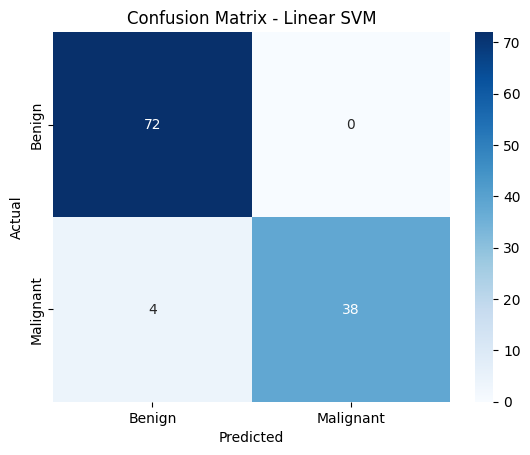

              precision    recall  f1-score   support

      Benign       0.95      1.00      0.97        72
   Malignant       1.00      0.90      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.95      0.96       114
weighted avg       0.97      0.96      0.96       114



In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

cm_linear = confusion_matrix(y_test, y_pred_linear)

sns.heatmap(
    cm_linear,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Benign', 'Malignant'],
    yticklabels=['Benign', 'Malignant']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Linear SVM')
plt.show()

print(classification_report(
    y_test,
    y_pred_linear,
    target_names=['Benign', 'Malignant']
))

In [ ]:
from sklearn.svm import SVC

svm_rbf = SVC(kernel='rbf')

svm_rbf.fit(X_train_scaled, y_train)

y_pred_rbf = svm_rbf.predict(X_test_scaled)

print("First 20 predictions:")
print(y_pred_rbf[:20])

First 20 predictions:
[0 1 0 0 0 0 1 0 0 0 1 0 1 0 0 0 0 0 0 0]


In [ ]:
from sklearn.metrics import accuracy_score

accuracy_rbf = accuracy_score(y_test, y_pred_rbf)

print("Nonlinear SVM (RBF) Accuracy:", accuracy_rbf)
print("Accuracy percentage:", accuracy_rbf * 100, "%")

Nonlinear SVM (RBF) Accuracy: 0.9736842105263158
Accuracy percentage: 97.36842105263158 %


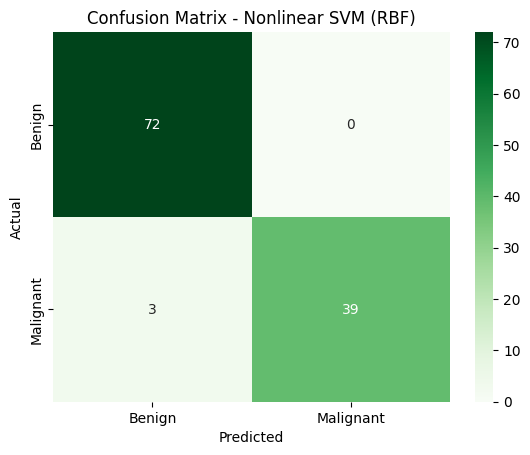

              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        72
   Malignant       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

cm_rbf = confusion_matrix(y_test, y_pred_rbf)

sns.heatmap(
    cm_rbf,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Benign', 'Malignant'],
    yticklabels=['Benign', 'Malignant']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Nonlinear SVM (RBF)')
plt.show()

print(classification_report(
    y_test,
    y_pred_rbf,
    target_names=['Benign', 'Malignant']
))